# LinkedIn Jobs & Skills (2024): Skill Analysis + ML Models (v2)

Dataset: [1.3M LinkedIn Jobs & Skills (2024)](https://www.kaggle.com/datasets/asaniczka/1-3m-linkedin-jobs-and-skills-2024)

**v2 mein kya behtar hua:**
- 2000 skills ki vocabulary (pehle sirf 100/300 thi)
- Ek skill ke mukhtalif naam khud merge hote hain (`problemsolving` = `problem solving`, `communication skills` = `communication`)
- Naya **Similar-Jobs Skill Recommender**: milti-julti job titles dhoond kar un ki skills nikalta hai. Har field ke liye kaam karta hai (CS, nursing, sales, finance...)
- Technical skills aur general skills alag alag
- Job level model ab 2000 skills dekhta hai, aur batata hai ke kaunse words/skills Senior ya Associate ki taraf le jate hain

Upar se neeche har cell chalayein, ya **Run All** dabayein.

## ⚙️ Settings

In [21]:
SAMPLE_SIZE = 200_000   # 8GB RAM wale Mac par 100_000 kar dein
VOCAB_SIZE = 2000       # kitni skills model ko yaad rakhni hain
K_NEIGHBORS = 50        # recommender kitne milte-julte titles dekhe
USE_EMBEDDINGS = True   # Phase 7 (sentence-transformers) chalana hai ya nahi
DATA_PATH = None        # None = Kaggle se khud download hoga
RANDOM_STATE = 42

In [26]:
import os
os.chdir("/Users/muhammadaadil/This Pc/Programming/Ai Projects/Linkdin_Profile/linkedin-skills-project")
print("Ab yahan hain:", os.getcwd())

Ab yahan hain: /Users/muhammadaadil/This Pc/Programming/Ai Projects/Linkdin_Profile/linkedin-skills-project


## 📦 Imports aur folders

In [27]:
import os, re, json, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy import sparse

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import classification_report, f1_score, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
for d in ["images", "models", "results"]:
    os.makedirs(d, exist_ok=True)

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#a8a69f"
TEXT, TEXT2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": "#d6d4ce", "axes.labelcolor": TEXT2,
    "xtick.color": TEXT2, "ytick.color": TEXT2, "text.color": TEXT,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 14,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def save_fig(name):
    path = f"images/{name}.png"
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("Saved:", path)
    plt.show()

def barh_chart(series, title, xlabel, name, color=BLUE):
    s = series.sort_values()
    fig, ax = plt.subplots(figsize=(9, 0.35 * len(s) + 1.2))
    ax.barh(s.index, s.values, color=color, height=0.6)
    ax.set_title(title); ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    for i, v in enumerate(s.values):
        ax.text(v, i, f" {v:,.0f}" if v >= 1 else f" {v:.0%}", va="center", fontsize=9, color=TEXT2)
    save_fig(name)

results = {}

## Phase 1: Data load

`job_summary.csv` bohot bari file hai, is liye load nahi karte. Skills file chunks mein parhte hain taake RAM full na ho.

In [29]:
if DATA_PATH is None:
    import kagglehub
    DATA_PATH = kagglehub.dataset_download("asaniczka/1-3m-linkedin-jobs-and-skills-2024")

print("Data folder:", DATA_PATH)
print("Files:", os.listdir(DATA_PATH))

postings_file = os.path.join(DATA_PATH, "linkedin_job_postings.csv")
skills_file = os.path.join(DATA_PATH, "job_skills.csv")
assert os.path.exists(postings_file), "linkedin_job_postings.csv nahi mili, upar Files list check karein"
assert os.path.exists(skills_file), "job_skills.csv nahi mili, upar Files list check karein"

jobs = pd.read_csv(postings_file, usecols=["job_link", "job_title", "job_level"]).dropna()
print("Total jobs:", len(jobs))

jobs = jobs.sample(n=min(int(SAMPLE_SIZE * 1.3), len(jobs)), random_state=RANDOM_STATE)
links = set(jobs.job_link)
parts = [chunk[chunk.job_link.isin(links)] for chunk in pd.read_csv(skills_file, chunksize=200_000)]
skills = pd.concat(parts, ignore_index=True)

df = jobs.merge(skills, on="job_link").dropna(subset=["job_skills"])
df = df.sample(n=min(SAMPLE_SIZE, len(df)), random_state=RANDOM_STATE).reset_index(drop=True)
del jobs, skills, parts
print("Final data:", df.shape)
df.head()

Data folder: /Users/muhammadaadil/.cache/kagglehub/datasets/asaniczka/1-3m-linkedin-jobs-and-skills-2024/versions/2
Files: ['job_skills.csv', 'job_summary.csv', 'linkedin_job_postings.csv']
Total jobs: 1348454
Final data: (200000, 4)


,job_link,job_title,job_level,job_skills
0,https://www.linkedin.com/jobs/view/usa-bakery-...,(USA) Bakery Lead,Mid senior,"Bakery production, Supervising associates, Foo..."
1,https://www.linkedin.com/jobs/view/senior-grou...,Senior Group Sales Manager - Limelight Denver,Mid senior,"Sales strategy, Group sales, Guestroom contrac..."
2,https://www.linkedin.com/jobs/view/senior-fina...,"Senior Financial Analyst, Business Planning - ...",Mid senior,"budgeting, reporting, financial modeling, cros..."
3,https://www.linkedin.com/jobs/view/food-innova...,Food Innovation Scientist,Mid senior,"Food Innovation, Product Development, R&D, Man..."
4,https://www.linkedin.com/jobs/view/sales-lead-...,Sales Lead,Mid senior,"Sales skills, Customer service skills, Retail ..."


## Phase 2: Skills cleaning (v2)

3 qadam:
1. **Basic cleaning:** lowercase, "excellent communication skills" se "communication"
2. **Manual synonyms:** jaise `reactjs` aur `react.js` se `react`
3. **Automatic merge:** jin naamon ke sirf space/dash/dot ka farq ho (`problem-solving`, `problemsolving`, `problem solving`) unhe sab se zyada istemal hone wale naam mein jor dena

In [30]:
MANUAL = {
    "reactjs": "react", "react.js": "react", "react js": "react",
    "nodejs": "node.js", "node": "node.js", "node js": "node.js",
    "vuejs": "vue.js", "vue": "vue.js", "angularjs": "angular",
    "python programming": "python", "python 3": "python", "python3": "python",
    "js": "javascript", "javascript es6": "javascript",
    "ml": "machine learning", "ai": "artificial intelligence", "dl": "deep learning",
    "amazon web services": "aws", "amazon web services (aws)": "aws",
    "google cloud platform": "gcp", "microsoft azure": "azure",
    "ms excel": "excel", "microsoft excel": "excel", "ms office": "microsoft office",
    "postgres": "postgresql", "structured query language": "sql",
    "rn": "registered nurse", "bls certification": "bls",
}
LEADING_RE = r"^(strong|excellent|good|effective|advanced|basic|solid|proven|exceptional)\s+"
TRAILING_RE = r"\s+(skills?|abilities|ability)$"

def basic_clean(x):
    x = re.sub(r"\s+", " ", x.strip().lower())
    x = re.sub(LEADING_RE, "", x)
    x = re.sub(TRAILING_RE, "", x)
    return MANUAL.get(x, x).strip()

def key_of(x):
    return re.sub(r"[^a-z0-9+#]", "", x)

raw_lists = df["job_skills"].astype(str).apply(lambda s: [basic_clean(x) for x in s.split(",") if x.strip()])

# Har "key" ke liye sab se zyada istemal hone wala naam
form_counts = Counter(x for L in raw_lists for x in L if x)
groups = {}
for form, c in form_counts.items():
    k = key_of(form)
    if k:
        groups.setdefault(k, []).append((c, form))
canonical_by_key = {}
for k, forms in groups.items():
    forms.sort(reverse=True)
    best_c, best = forms[0]
    spaced = [(c, f) for c, f in forms if " " in f]
    # "problemsolving" ke bajaye "problem solving" jaisa parhne mein aasan naam
    if " " not in best and spaced and spaced[0][0] >= 0.2 * best_c:
        best = spaced[0][1]
    canonical_by_key[k] = best

df["skill_list"] = [sorted({canonical_by_key[key_of(x)] for x in L if key_of(x)}) for L in raw_lists]
del raw_lists

counts = Counter(s for L in df.skill_list for s in L)
vocab = [s for s, _ in counts.most_common(VOCAB_SIZE)]
vocab_set = set(vocab)
df["skill_list"] = df.skill_list.apply(lambda L: [s for s in L if s in vocab_set])
df = df[df.skill_list.str.len() > 0].copy()

df["title_clean"] = (df.job_title.str.lower()
                     .str.replace(r"[^a-z ]", " ", regex=True)
                     .str.replace(r"\s+", " ", regex=True).str.strip())
df = df[df.title_clean.str.len() > 0]

level_counts = df.job_level.value_counts()
df = df[df.job_level.isin(level_counts[level_counts >= 100].index)].copy()

print("Rows after cleaning:", len(df))
print("Unique skill names before merge:", len(form_counts), "| after merge:", len(counts))
print("Vocabulary size:", len(vocab))

Rows after cleaning: 197248
Unique skill names before merge: 712037 | after merge: 692675
Vocabulary size: 2000


### General (soft) skills ki pehchaan

Ye har field mein hoti hain, is liye recommender inhe technical skills se alag dikhata hai.

In [33]:
GENERIC_RE = (r"communicat|teamwork|teamplayer|collaborat|leadership|problemsolving|criticalthinking|"
              r"attentiontodetail|detailoriented|timemanagement|organizational|interpersonal|multitask|"
              r"adaptab|flexibility|selfmotivat|workethic|workindependently|decisionmaking|^creativity$|"
              r"customerservice|degree|diploma|bachelor|yearsof|^english$|^analytical$|analyticalthinking|"
              r"reliab|punctual|professionalism|positiveattitude|prioritiz|^organization$")

def is_generic(skill):
    return re.search(GENERIC_RE, key_of(skill)) is not None

generic_mask = np.array([is_generic(s) for s in vocab])
print("General skills in vocab:", generic_mask.sum(), "| Technical/field skills:", (~generic_mask).sum())
print("Examples of general:", [s for s, g in zip(vocab, generic_mask) if g][:15])

General skills in vocab: 100 | Technical/field skills: 1900
Examples of general: ['communication', 'problem solving', 'customer service', 'teamwork', 'leadership', 'time management', 'attention to detail', 'interpersonal', 'collaboration', 'organizational', "bachelor's degree", 'high school diploma', 'analytical', 'multitasking', 'decision making']


## Phase 3: EDA (charts `images/` mein save hongi)

Saved: images/01_top_skills.png


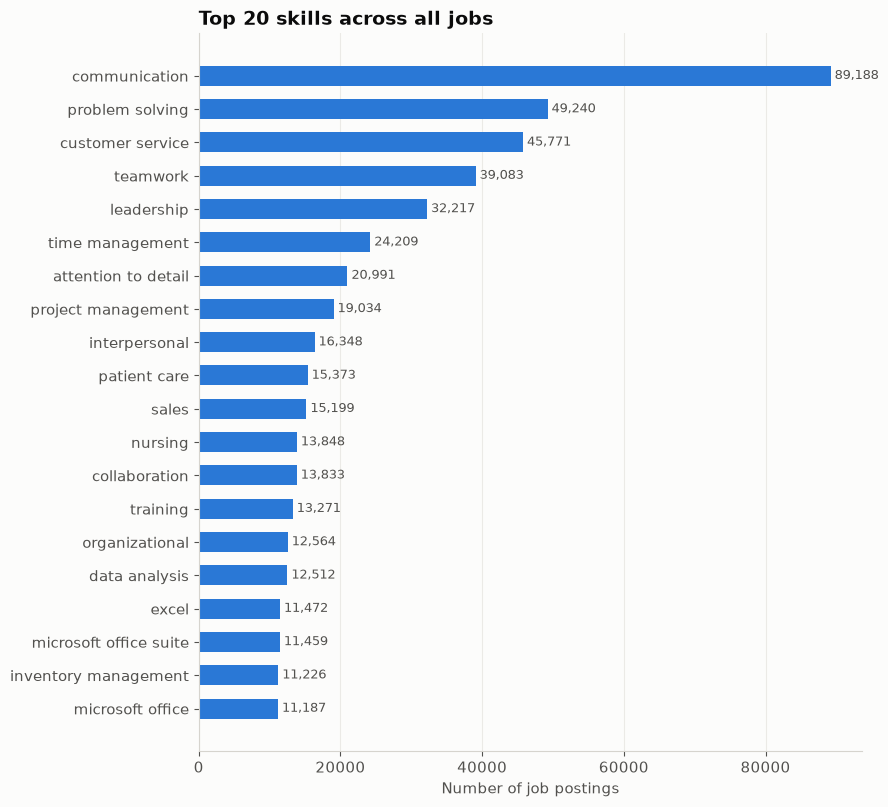

Saved: images/01b_top_technical_skills.png


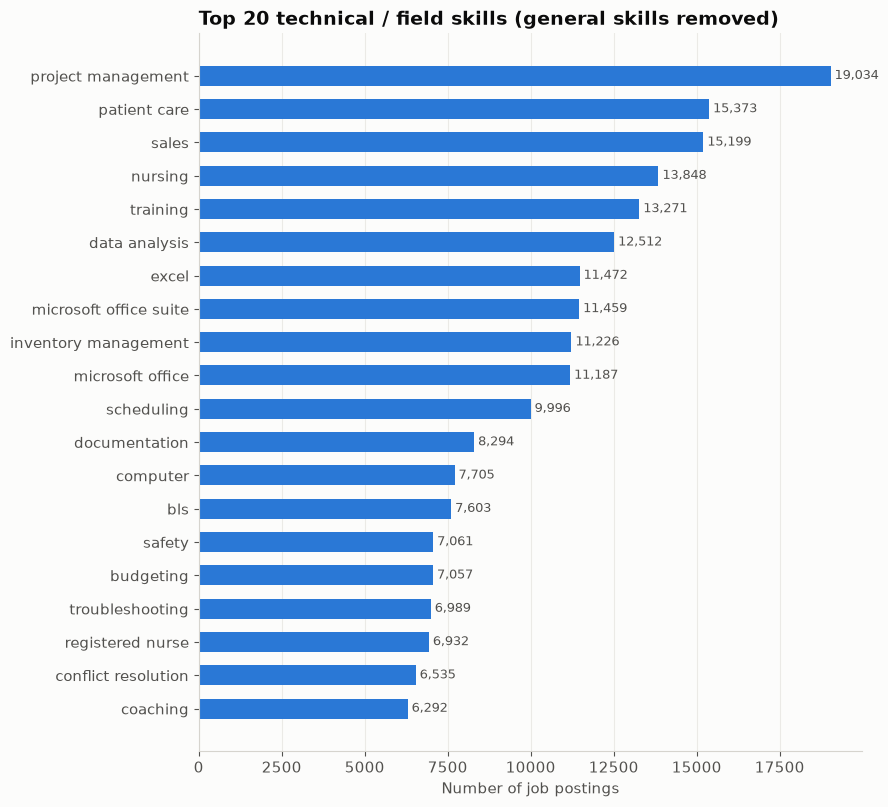

In [34]:
top20_all = pd.Series(dict(counts.most_common(20)))
barh_chart(top20_all, "Top 20 skills across all jobs", "Number of job postings", "01_top_skills")

tech_counts = {s: c for s, c in counts.most_common() if s in vocab_set and not is_generic(s)}
top20_tech = pd.Series(dict(list(tech_counts.items())[:20]))
barh_chart(top20_tech, "Top 20 technical / field skills (general skills removed)", "Number of job postings", "01b_top_technical_skills")

Saved: images/02_job_levels.png


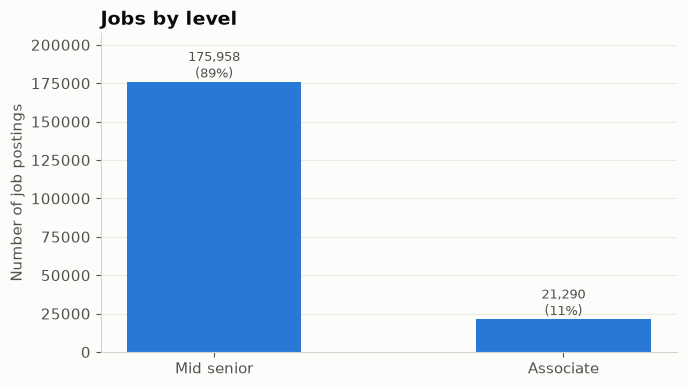

In [35]:
lv = df.job_level.value_counts()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(lv.index, lv.values, color=BLUE, width=0.5)
ax.set_title("Jobs by level"); ax.set_ylabel("Number of job postings")
ax.grid(axis="x", visible=False)
for i, v in enumerate(lv.values):
    ax.text(i, v, f"{v:,}\n({v/lv.sum():.0%})", ha="center", va="bottom", fontsize=9, color=TEXT2)
ax.set_ylim(0, lv.max() * 1.18)
save_fig("02_job_levels")

CS/tech jobs in sample: 3924
Saved: images/03_tech_skills.png


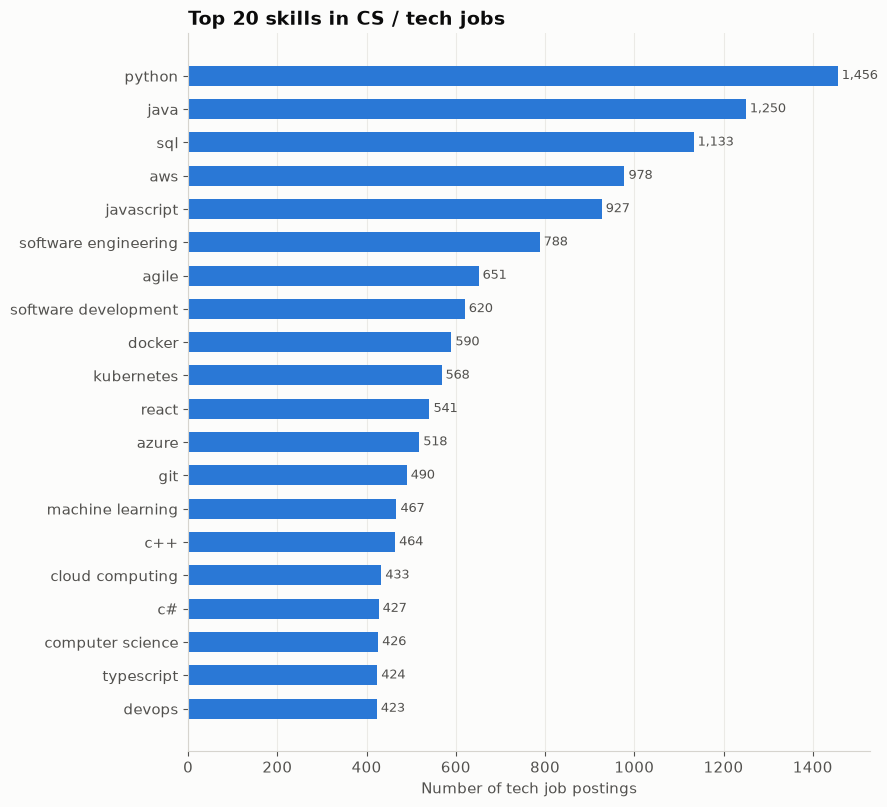

In [36]:
tech_pattern = r"software|developer|data scientist|data engineer|full stack|machine learning|backend|frontend|web dev"
tech = df[df.title_clean.str.contains(tech_pattern, regex=True)]
print("CS/tech jobs in sample:", len(tech))
if len(tech) > 0:
    tc = Counter(s for L in tech.skill_list for s in L if not is_generic(s))
    barh_chart(pd.Series(dict(tc.most_common(20))), "Top 20 skills in CS / tech jobs",
               "Number of tech job postings", "03_tech_skills")

## Phase 4: Train/Test split

In [37]:
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df.job_level, random_state=RANDOM_STATE)
train_df = train_df.reset_index(drop=True); test_df = test_df.reset_index(drop=True)
print("Train:", len(train_df), " Test:", len(test_df))

Train: 157798  Test: 39450


## Phase 5: Model 1, Job Level Classifier 🎯

Skills (2000) + job title ke words se job level predict karta hai.

In [38]:
lvl_mlb = MultiLabelBinarizer(classes=vocab, sparse_output=True)
lvl_tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)

X_train = sparse.hstack([lvl_mlb.fit_transform(train_df.skill_list),
                         lvl_tfidf.fit_transform(train_df.title_clean)]).tocsr()
X_test = sparse.hstack([lvl_mlb.transform(test_df.skill_list),
                        lvl_tfidf.transform(test_df.title_clean)]).tocsr()
y_train, y_test = train_df.job_level, test_df.job_level

base_pred = DummyClassifier(strategy="most_frequent").fit(X_train, y_train).predict(X_test)
clf = LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5)
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

print("=== Baseline ===\n", classification_report(y_test, base_pred, zero_division=0))
print("=== Our model ===\n", classification_report(y_test, pred))
results["job_level_baseline_f1_macro"] = round(f1_score(y_test, base_pred, average="macro"), 3)
results["job_level_model_f1_macro"] = round(f1_score(y_test, pred, average="macro"), 3)
results["job_level_model_accuracy"] = round(float((pred == y_test).mean()), 3)

=== Baseline ===
               precision    recall  f1-score   support

   Associate       0.00      0.00      0.00      4258
  Mid senior       0.89      1.00      0.94     35192

    accuracy                           0.89     39450
   macro avg       0.45      0.50      0.47     39450
weighted avg       0.80      0.89      0.84     39450

=== Our model ===
               precision    recall  f1-score   support

   Associate       0.34      0.77      0.47      4258
  Mid senior       0.97      0.82      0.89     35192

    accuracy                           0.81     39450
   macro avg       0.65      0.79      0.68     39450
weighted avg       0.90      0.81      0.84     39450



Saved: images/04_confusion_matrix.png


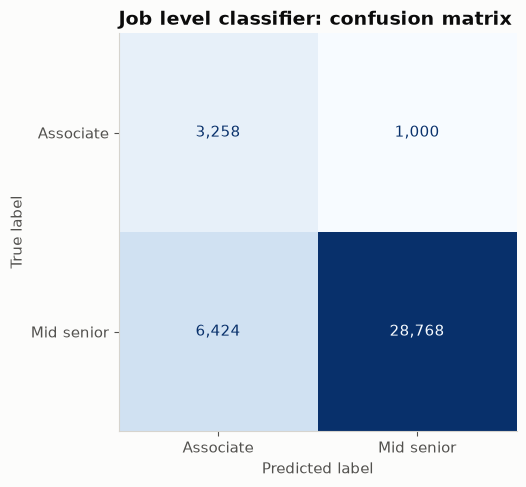

Saved: images/07_level_signals.png


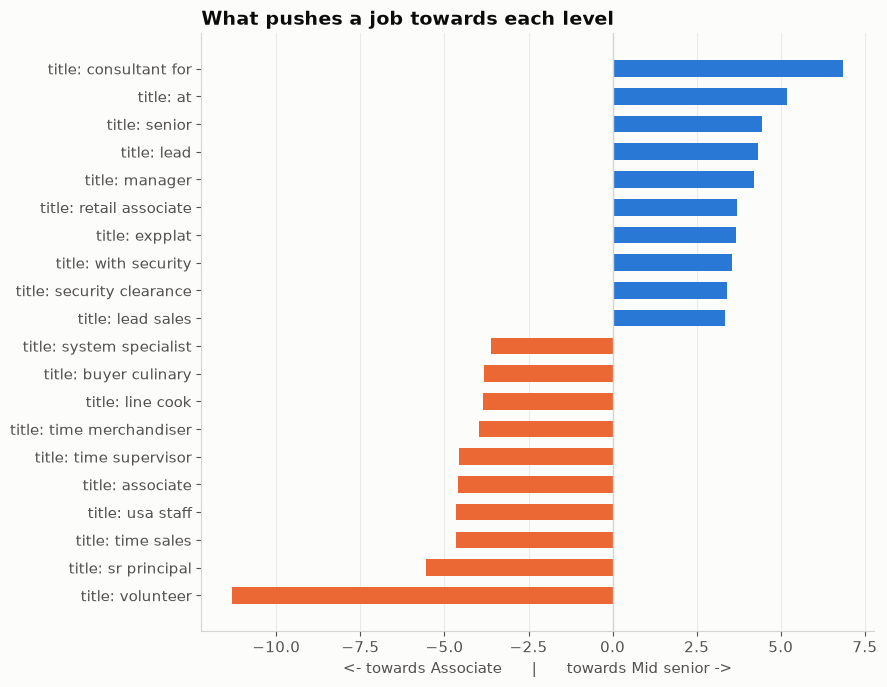

In [39]:
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, pred, labels=clf.classes_)
ConfusionMatrixDisplay(cm, display_labels=clf.classes_).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
ax.grid(False); ax.set_title("Job level classifier: confusion matrix")
save_fig("04_confusion_matrix")

# Kaunse words / skills kis level ki taraf le jate hain
feature_names = [f"skill: {s}" for s in vocab] + [f"title: {w}" for w in lvl_tfidf.get_feature_names_out()]
if len(clf.classes_) == 2:
    coef = clf.coef_[0]
    order = np.argsort(coef)
    idx = np.r_[order[:10], order[-10:]]
    fig, ax = plt.subplots(figsize=(9, 7))
    colors = [ORANGE if coef[i] < 0 else BLUE for i in idx]
    ax.barh([feature_names[i] for i in idx], coef[idx], color=colors, height=0.6)
    ax.axvline(0, color="#d6d4ce", linewidth=1)
    ax.set_title("What pushes a job towards each level")
    ax.set_xlabel(f"<- towards {clf.classes_[0]}      |      towards {clf.classes_[1]} ->")
    ax.grid(axis="y", visible=False)
    save_fig("07_level_signals")

## Phase 6: Model 2, Similar-Jobs Skill Recommender 🎯

**Ye kaise kaam karta hai:**
1. Train data ke har unique job title ke liye ginti karte hain ke us title ki kitni jobs mein kaunsi skill thi.
2. Naya title aaye to **character TF-IDF** se 50 sab se milte-julte titles dhoondte hain (`Full-Stack Engineer`, `Fullstack Developer` bhi match ho jate hain).
3. Un titles ki skills jor kar har skill ka **% of similar jobs** nikalte hain.
4. Technical skills ko **lift** se rank karte hain: jo skill is job mein baqi jobs se zyada aam hai wo upar. Is se `communication` jaisi har jagah wali skills neeche chali jati hain.

In [40]:
rec_mlb = MultiLabelBinarizer(classes=vocab, sparse_output=True)
X_sk = rec_mlb.fit_transform(train_df.skill_list).astype(np.float32).tocsr()
p_global = np.asarray(X_sk.mean(axis=0)).ravel()

codes, uniq_titles = pd.factorize(train_df.title_clean)
G = sparse.csr_matrix((np.ones(len(codes), dtype=np.float32), (codes, np.arange(len(codes)))),
                      shape=(len(uniq_titles), len(codes)))
S = (G @ X_sk).tocsr()                          # title x skill: kitni jobs mein skill thi
n_jobs = np.asarray(G.sum(axis=1)).ravel()      # har title ki total jobs
uniq_titles = np.asarray(uniq_titles)
print("Unique train titles:", len(uniq_titles))

title_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True)
T = title_vec.fit_transform(uniq_titles)
nn_tfidf = NearestNeighbors(n_neighbors=K_NEIGHBORS, metric="cosine", algorithm="brute").fit(T)

def skill_probs(query_matrix, nn, k=K_NEIGHBORS):
    # har query ke liye: har skill kitne % milti-julti jobs mein hai
    dist, idx = nn.kneighbors(query_matrix, n_neighbors=k)
    sim = np.clip(1 - dist, 0, 1)
    w = sim ** 2
    q = query_matrix.shape[0]
    W = sparse.csr_matrix((w.ravel(), (np.repeat(np.arange(q), k), idx.ravel())), shape=(q, len(uniq_titles)))
    num = (W @ S).toarray()
    den = W @ n_jobs
    P = num / np.maximum(den[:, None], 1e-9)
    return P, sim.max(axis=1), idx

def tech_score(P):
    # lift-weighted: is job ke liye khaas skills upar
    s = P * np.log1p(P / np.maximum(p_global, 1e-6))
    s[:, generic_mask] = -1
    return s

Unique train titles: 87479


### Evaluation: Precision@10

Test data ki har job ke liye 10 skills recommend karte hain aur dekhte hain ke un mein se kitni waqai us job mein theen. Muqabla ek **baseline** se hai jo har job ko sab se mashhoor skills bata deta hai.

In [41]:
Y_test = rec_mlb.transform(test_df.skill_list).tocsr()
test_codes, test_uniq = pd.factorize(test_df.title_clean)
test_uniq = np.asarray(test_uniq)

def evaluate(make_queries, nn, batch=500, k_rec=10):
    # do scores: (a) saari skills par, (b) sirf technical skills par
    hits_all, hits_tech, n_all, n_tech = 0.0, 0.0, 0, 0
    tech_cols = set(np.where(~generic_mask)[0])
    rows_by_title = pd.Series(np.arange(len(test_codes))).groupby(test_codes).apply(list)
    for start in range(0, len(test_uniq), batch):
        ids = np.arange(start, min(start + batch, len(test_uniq)))
        P, _, _ = skill_probs(make_queries(test_uniq[ids]), nn)
        top_all = np.argsort(-P, axis=1)[:, :k_rec]
        top_tech = np.argsort(-tech_score(P), axis=1)[:, :k_rec]
        for j, t in enumerate(ids):
            for r in rows_by_title[t]:
                true = set(Y_test[r].indices)
                if true:
                    hits_all += len(true & set(top_all[j])) / k_rec; n_all += 1
                true_t = true & tech_cols
                if true_t:
                    hits_tech += len(true_t & set(top_tech[j])) / k_rec; n_tech += 1
    return hits_all / max(n_all, 1), hits_tech / max(n_tech, 1)

def baseline_eval(k_rec=10):
    top_all = set(np.argsort(-p_global)[:k_rec])
    g = p_global.copy(); g[generic_mask] = -1
    top_tech = set(np.argsort(-g)[:k_rec])
    tech_cols = set(np.where(~generic_mask)[0])
    ha, ht, na, nt = 0.0, 0.0, 0, 0
    for r in range(Y_test.shape[0]):
        true = set(Y_test[r].indices)
        if true: ha += len(true & top_all) / k_rec; na += 1
        tt = true & tech_cols
        if tt: ht += len(tt & top_tech) / k_rec; nt += 1
    return ha / max(na, 1), ht / max(nt, 1)

b_all, b_tech = baseline_eval()
m_all, m_tech = evaluate(lambda titles: title_vec.transform(titles), nn_tfidf)
results.update({
    "recommender_baseline_p10_all": round(b_all, 3), "recommender_baseline_p10_technical": round(b_tech, 3),
    "recommender_tfidf_p10_all": round(m_all, 3), "recommender_tfidf_p10_technical": round(m_tech, 3),
})
print(f"Precision@10 (all skills)       baseline: {b_all:.3f} | model: {m_all:.3f}")
print(f"Precision@10 (technical skills) baseline: {b_tech:.3f} | model: {m_tech:.3f}")

Precision@10 (all skills)       baseline: 0.179 | model: 0.309
Precision@10 (technical skills) baseline: 0.069 | model: 0.216


In [43]:
def recommend(title, k_tech=10, k_general=5):
    q = re.sub(r"\s+", " ", re.sub(r"[^a-z ]", " ", title.lower())).strip()
    P, best_sim, idx = skill_probs(title_vec.transform([q]), nn_tfidf)
    P = P[0]
    tech_idx = np.argsort(-tech_score(P[None, :])[0])[:k_tech]
    tech_idx = sorted(tech_idx, key=lambda i: -P[i])   # lift se chuni, % se dikhayi
    gen_idx = [i for i in np.argsort(-P) if generic_mask[i]][:k_general]
    return {
        "technical": [(vocab[i], float(P[i])) for i in tech_idx if P[i] >= 0.15],
        "general": [(vocab[i], float(P[i])) for i in gen_idx if P[i] > 0],
        "similar_titles": list(uniq_titles[idx[0][:5]]),
        "match_score": float(best_sim[0]),
    }

demo_titles = ["full stack developer", "data scientist", "machine learning engineer",
               "registered nurse", "accountant", "sales manager", "graphic designer", "civil engineer"]
demo = {}
for t in demo_titles:
    r = recommend(t)
    if r["match_score"] < 0.3 or not r["technical"]:
        print(f"{t}: sample mein milta-julta title nahi mila")
        continue
    demo[t] = [s for s, _ in r["technical"][:6]]
    print(f"\n{t}  (similar: {', '.join(r['similar_titles'][:3])})")
    print("  technical:", ", ".join(f"{s} ({p:.0%})" for s, p in r["technical"][:8]))
    print("  general:  ", ", ".join(f"{s} ({p:.0%})" for s, p in r["general"]))


full stack developer  (similar: full stack developer, lead full stack developer, developer full stack senior)
  technical: javascript (50%), react (39%), angular (34%), java (32%), html (26%), css (25%), git (24%), node.js (23%)
  general:   communication (31%), problem solving (24%), teamwork (9%), collaboration (7%), time management (5%)

data scientist  (similar: data scientist, data scientist senior data scientist, lead data scientist)
  technical: python (41%), machine learning (38%), data analysis (37%), data science (35%), sql (30%), data visualization (24%), statistics (23%), r (23%)
  general:   communication (40%), problem solving (32%), teamwork (16%), collaboration (12%), attention to detail (8%)

machine learning engineer  (similar: machine learning engineer, sr machine learning engineer, lead machine learning engineer)
  technical: python (84%), machine learning (78%), tensorflow (58%), pytorch (52%), aws (33%), deep learning (27%), java (26%), gcp (24%)
  general:   com

Saved: images/05_recommendations.png


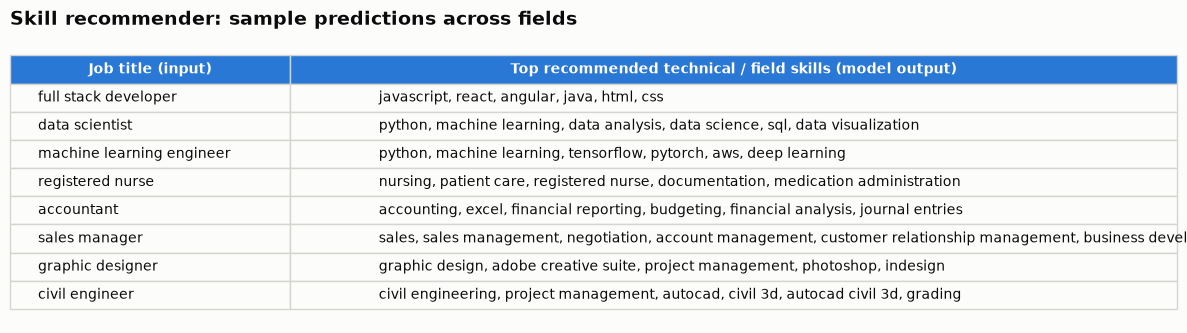

In [44]:
if demo:
    fig, ax = plt.subplots(figsize=(12, 0.32 * len(demo) + 0.9))
    ax.axis("off")
    table = ax.table(cellText=[[t, ", ".join(s)] for t, s in demo.items()],
                     colLabels=["Job title (input)", "Top recommended technical / field skills (model output)"],
                     colWidths=[0.24, 0.76], cellLoc="left", loc="center")
    table.auto_set_font_size(False); table.set_fontsize(10); table.scale(1, 1.6)
    for (r, c), cell in table.get_celld().items():
        cell.set_edgecolor("#d6d4ce")
        if r == 0:
            cell.set_text_props(weight="bold", color="white"); cell.set_facecolor(BLUE)
        else:
            cell.set_facecolor(SURFACE)
    ax.set_title("Skill recommender: sample predictions across fields", pad=12)
    save_fig("05_recommendations")

## Phase 7: Embeddings se milte-julte titles (optional)

Character TF-IDF sirf spelling dekhta hai. Embeddings matlab samajhti hain (`ML Engineer` aur `Machine Learning Engineer`). Mac par Apple chip (`mps`) khud use hoga.

In [45]:
emb_ready = False
if USE_EMBEDDINGS:
    try:
        import torch
        from sentence_transformers import SentenceTransformer
        device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
        print("Device:", device)
        emb_model = SentenceTransformer("all-MiniLM-L6-v2", device=device)
        E_titles = emb_model.encode(list(uniq_titles), batch_size=256, show_progress_bar=True, normalize_embeddings=True)
        nn_emb = NearestNeighbors(n_neighbors=K_NEIGHBORS, metric="cosine", algorithm="brute").fit(E_titles)
        e_all, e_tech = evaluate(lambda titles: emb_model.encode(list(titles), batch_size=256, normalize_embeddings=True), nn_emb)
        results["recommender_embeddings_p10_all"] = round(e_all, 3)
        results["recommender_embeddings_p10_technical"] = round(e_tech, 3)
        emb_ready = True
        print(f"Precision@10 technical  TF-IDF: {m_tech:.3f}  vs  Embeddings: {e_tech:.3f}")
    except Exception as e:
        print("Embeddings phase skip hua:", repr(e))
else:
    print("USE_EMBEDDINGS = False, phase skip.")

Device: mps


Batches: 100%|██████████| 342/342 [00:11<00:00, 28.99it/s]


Precision@10 technical  TF-IDF: 0.216  vs  Embeddings: 0.215


## 📊 Model comparison chart

Saved: images/06_model_comparison.png


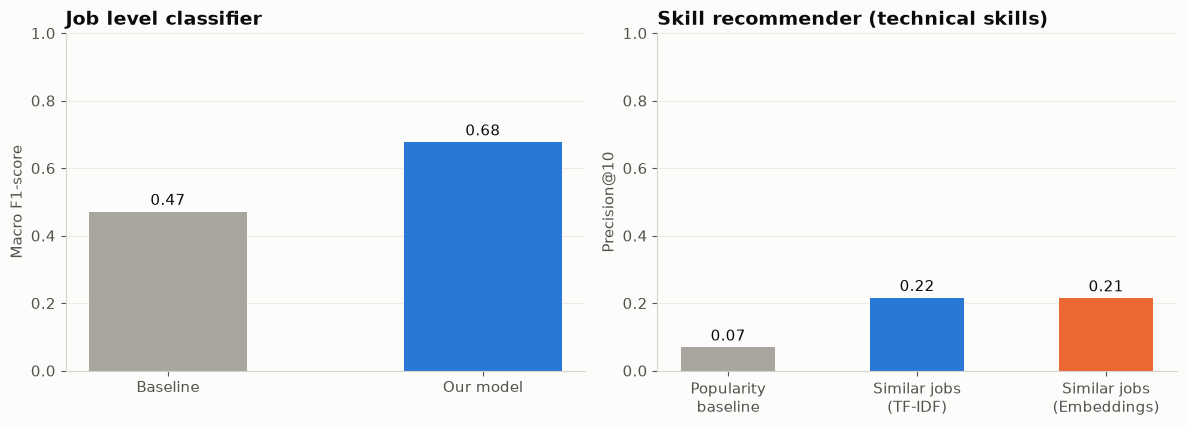

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
v1 = [results["job_level_baseline_f1_macro"], results["job_level_model_f1_macro"]]
ax.bar(["Baseline", "Our model"], v1, color=[GRAY, BLUE], width=0.5)
ax.set_title("Job level classifier"); ax.set_ylabel("Macro F1-score")

ax2 = axes[1]
n2 = ["Popularity\nbaseline", "Similar jobs\n(TF-IDF)"]
v2 = [results["recommender_baseline_p10_technical"], results["recommender_tfidf_p10_technical"]]
c2 = [GRAY, BLUE]
if emb_ready:
    n2.append("Similar jobs\n(Embeddings)"); v2.append(results["recommender_embeddings_p10_technical"]); c2.append(ORANGE)
ax2.bar(n2, v2, color=c2, width=0.5)
ax2.set_title("Skill recommender (technical skills)"); ax2.set_ylabel("Precision@10")
for a, vs in [(ax, v1), (ax2, v2)]:
    a.set_ylim(0, 1); a.grid(axis="x", visible=False)
    for i, v in enumerate(vs):
        a.text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=11, color=TEXT)
save_fig("06_model_comparison")

## Phase 8: Models aur results save

`predict.py` inhi files ko use karti hai.

In [47]:
cleaner = {"manual": MANUAL, "leading_re": LEADING_RE, "trailing_re": TRAILING_RE,
           "generic_re": GENERIC_RE, "canonical_by_key": canonical_by_key}
joblib.dump(cleaner, "models/cleaner.pkl")
joblib.dump({"clf": clf, "mlb": lvl_mlb, "tfidf": lvl_tfidf}, "models/level_model.pkl")
joblib.dump({"title_vec": title_vec, "nn": nn_tfidf, "S": S, "n_jobs": n_jobs, "uniq_titles": uniq_titles,
             "vocab": vocab, "p_global": p_global, "generic_mask": generic_mask, "k": K_NEIGHBORS},
            "models/recommender.pkl")

results["rows_used"] = int(len(df))
results["vocab_size"] = len(vocab)
results["sample_recommendations"] = demo
with open("results/metrics.json", "w") as f:
    json.dump(results, f, indent=2)

print("Saved models:", sorted(os.listdir("models")))
print("Charts:", sorted(os.listdir("images")))
print(json.dumps({k: v for k, v in results.items() if k != "sample_recommendations"}, indent=2))

Saved models: ['cleaner.pkl', 'level_model.pkl', 'recommender.pkl']
Charts: ['01_top_skills.png', '01b_top_technical_skills.png', '02_job_levels.png', '03_tech_skills.png', '04_confusion_matrix.png', '05_recommendations.png', '06_model_comparison.png', '07_level_signals.png']
{
  "job_level_baseline_f1_macro": 0.471,
  "job_level_model_f1_macro": 0.677,
  "job_level_model_accuracy": 0.812,
  "recommender_baseline_p10_all": 0.179,
  "recommender_baseline_p10_technical": 0.069,
  "recommender_tfidf_p10_all": 0.309,
  "recommender_tfidf_p10_technical": 0.216,
  "recommender_embeddings_p10_all": 0.306,
  "recommender_embeddings_p10_technical": 0.215,
  "rows_used": 197248,
  "vocab_size": 2000
}
